# Qian et al. 2020 — Breast Cancer · 02 EMT-TF Expression
The EMT-transcription-factor readout is **unconditional** — produced regardless of the gate outcome. Gate 1 was NO-GO (the malignant compartment clusters by patient and does not integrate), so there is no trajectory; the TFs are shown on the committed sample-integrated manifold. Categorical overlay of the two most-expressed, family-distinct EMT-TFs on a grey manifold (reference style — not a continuous colormap).

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

## Load processed data

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('cells:', adata.shape[0], '| Gate 1 =', adata.uns.get('gate1'))
print('reason:', adata.uns.get('gate1_reason'))

cells: 4818 | Gate 1 = NO-GO
reason: malignant compartment clusters by sample (dominant patient 54 = 65%); iLISI<=1.5/2.3 and embedding stays fragmented across theta 2-20 x n_pcs 20-40


## Score the EMT-TF panel
Panel spans Snail/Zeb/Twist plus the mesenchymal FOXC and PRRX families (per the Kürten/Chen lesson — do not restrict to Snail/Zeb/Twist). Rank by detected fraction; the overlay shows the two most-expressed factors from *different* families so it is not degenerate.

In [4]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows = []
for j,g in enumerate(present):
    x = X[:,j]
    rows.append((g, round((x>0).mean(),3), round(x.mean(),3), round(x[x>0].mean() if (x>0).any() else 0,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_all','mean_expr']).sort_values('frac_expr', ascending=False)
print(df.to_string(index=False))
fam = {'SNAI1':'Snail','SNAI2':'Snail','ZEB1':'Zeb','ZEB2':'Zeb','TWIST1':'Twist','TWIST2':'Twist',
       'FOXC1':'FoxC','FOXC2':'FoxC','PRRX1':'Prrx','PRRX2':'Prrx'}
ok = df[df.frac_expr > 0.03].copy(); ok['fam'] = ok.TF.map(fam)
top = ok.iloc[0]['TF']; top_fam = fam[top]
second = ok[ok.fam != top_fam].iloc[0]['TF']
tf_a, tf_b = top, second
print(f'\nselected EMT-TFs (most-expressed, distinct families): {tf_a} ({fam[tf_a]}), {tf_b} ({fam[tf_b]})')

    TF  frac_expr  mean_all  mean_expr
 SNAI2      0.113     0.158      1.398
 FOXC1      0.104     0.049      0.473
 SNAI1      0.068     0.033      0.490
TWIST2      0.030     0.010      0.320
 PRRX1      0.026     0.013      0.512
 FOXC2      0.023     0.007      0.289
 PRRX2      0.019     0.005      0.270
  ZEB1      0.012     0.004      0.298
TWIST1      0.008     0.002      0.303
  ZEB2      0.005     0.002      0.478

selected EMT-TFs (most-expressed, distinct families): SNAI2 (Snail), FOXC1 (FoxC)


## Deliverable — expression.pdf
Categorical overlay: expressers (above the upper-quartile-of-expressers threshold) coloured on a grey manifold, marker size matched to the other deliverable panels, external legend, consistent orientation.

overlay thresholds (upper quartile among expressers): {'SNAI2': 1.903, 'FOXC1': 0.624} | cells shown: {'SNAI2': 137, 'FOXC1': 125}
SNAI2: 11.3% expressing; 137 cells shown (upper quartile)
FOXC1: 10.4% expressing; 125 cells shown (upper quartile)
saved expression.pdf


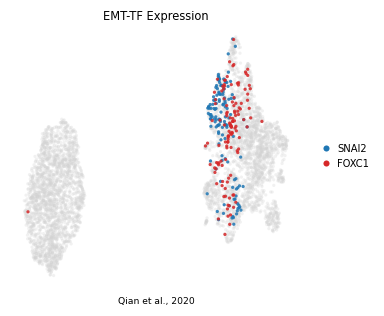

In [5]:
def vec(g):
    x = adata[:,g].X
    return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr = {}
for g in [tf_a, tf_b]:
    v = vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos, 0.75)) if pos.size else 0.0
sel = {g: vec(g) > thr[g] for g in [tf_a, tf_b]}
print('overlay thresholds (upper quartile among expressers):', {g: round(thr[g],3) for g in [tf_a,tf_b]},
      '| cells shown:', {g: int(sel[g].sum()) for g in [tf_a,tf_b]})
colors = {tf_a:'tab:blue', tf_b:'tab:red'}
order = sorted([tf_a, tf_b], key=lambda g: -int(sel[g].sum()))
xy = adata.obsm['X_umap']
xlo,xhi = np.percentile(xy[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xy[:,1],[0.3,99.7])
px=(xhi-xlo)*.06; py=(yhi-ylo)*.06
fig, ax = plt.subplots(figsize=(3.4, 3.0))
sc.pl.umap(adata, size=18, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=18, alpha=.85, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(yhi+py,ylo-py)
ax.legend(handles=[Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[tf_a],markersize=5,label=tf_a),
                   Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[tf_b],markersize=5,label=tf_b)],
          loc='center left', bbox_to_anchor=(1.02,.5), frameon=False, fontsize=6.5, handletextpad=.2)
ax.set_title('EMT-TF Expression', size=7.5)
ax.text(.5, -.08, 'Qian et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
plt.show()
for g in [tf_a, tf_b]:
    print(f'{g}: {(vec(g)>0).mean()*100:.1f}% expressing; {int(sel[g].sum())} cells shown (upper quartile)')
print('saved expression.pdf')